In [117]:
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain.chat_models import init_chat_model
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableParallel, RunnableLambda, RunnableBranch, RunnablePassthrough
import os
from dotenv import load_dotenv
from langchain_core.messages import HumanMessage, ToolMessage
from langchain.tools import tool
from IPython.display import Image, display

load_dotenv()

llm_openai= init_chat_model(model=os.environ.get("LLM_MODEL"), temperature = 0.7)
# generation = input("Enter your generation (e.g., GenZ, Millennial, GenX): ")

### ***Tools***

In [118]:
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_community.utilities import DuckDuckGoSearchAPIWrapper

@tool
def search_duckduckgo(query: str) -> str:

    """This tool searches the latest news on DuckDuckGo for the given query and returns the results."""
    duck_search = DuckDuckGoSearchRun(
        api_wrapper=DuckDuckGoSearchAPIWrapper(region="us-en", source="news")
    )
    return duck_search.invoke(query)

In [119]:
from langchain_community.tools import ArxivQueryRun
from langchain_community.utilities import ArxivAPIWrapper

@tool
def arxiv_tool(query: str) -> str:

    """This tool allows you to query the arXiv database for research papers."""
    arxiv_query = ArxivQueryRun(api_wrapper=ArxivAPIWrapper())
    return arxiv_query.invoke(query)

In [120]:
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper

@tool
def wiki_tool(query: str):

    """This tool allows you to search Wikipedia for information on a given topic."""
    wiki_query = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())
    return wiki_query.invoke(query)

In [121]:
@tool
def personal_info(name: str):

    """Use this tool to get personal information about Alice, Bob, or Charlie. 
    """

    info = {
        "Alice": "Alice is a software engineer with 5 years of experience in AI.",
        "Bob": "Bob is a data scientist who loves working with large datasets.",
        "Charlie": "Charlie is a product manager with a background in tech startups."
    }
    return info.get(name, "No information available for this person.")

### ***Tool Binding***

In [122]:
tools = [search_duckduckgo, arxiv_tool, wiki_tool, personal_info]

llm_with_tools = llm_openai.bind_tools(tools)

## ***LangGraph Creation***

### ***Create Schema***

In [123]:
from typing import TypedDict, List

class graph_schema(TypedDict):
    messages: List

### ***Create Node Functions***

In [124]:
def llm_node(state: graph_schema) -> graph_schema:
    messages = state["messages"]

    # System instructions + the full conversation so far
    prompt = ChatPromptTemplate.from_messages(
        [
            ("system", "You are a helpful assistant that can use tools to answer questions."),
            MessagesPlaceholder("messages"),
        ]
    )
    chain = prompt | llm_with_tools

    response = chain.invoke({"messages": messages})

    return {"messages": messages + [response]}

In [125]:
tools_by_name = {t.name: t for t in tools}

def tool_node(state: graph_schema) -> graph_schema:
    messages = state["messages"]

    tool_results = []

    for tool_call in messages[-1].tool_calls:
        selected_tool = tools_by_name[tool_call["name"]]

        try:
            obs = selected_tool.invoke(tool_call["args"])
        except Exception as e:
            obs = f"Tool error: {e}"

        tool_results.append(
            ToolMessage(content=str(obs), tool_call_id=tool_call["id"])
        )

    return {"messages": messages + tool_results}

###  ***Graph Creation via Conditional Edging***

In [126]:
# Conditional Edge Function

def if_tool_calls(state: graph_schema) -> str:
    last_message = state["messages"][-1]

    if last_message.tool_calls:
        return "tool_node"
    else:
        return "end"

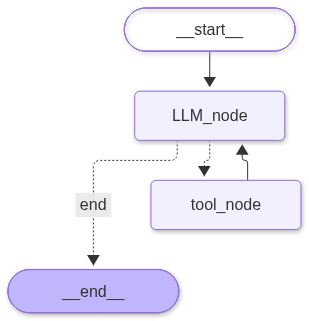

In [127]:
from langgraph.graph import START, END, StateGraph

graph = StateGraph(graph_schema)

graph.add_node("LLM_node", llm_node)
graph.add_node("tool_node", tool_node)

#Add edges between nodes
graph.add_edge(START, "LLM_node")
graph.add_conditional_edges("LLM_node", if_tool_calls, {"tool_node": "tool_node", "end": END})
graph.add_edge("tool_node", "LLM_node")

react_graph = graph.compile()

# You could see the errors with the below command
Image(react_graph.get_graph().draw_mermaid_png())

In [128]:
react_graph.invoke({"messages": [HumanMessage(content="What's the latest news about Argentina national football team?")]})

{'messages': [HumanMessage(content="What's the latest news about Argentina national football team?", additional_kwargs={}, response_metadata={}),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 25, 'prompt_tokens': 253, 'total_tokens': 278, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.4-2026-03-05', 'system_fingerprint': None, 'id': 'chatcmpl-EkpLA0SgyKOqsoGh6n1IFMpRxSpE3', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1e427-5fb5-7144-abf4-eeae2f6d9c86-0', tool_calls=[{'name': 'search_duckduckgo', 'args': {'query': 'latest news Argentina national football team'}, 'id': 'call_a

In [132]:
for chunk in react_graph.stream(
    {"messages": [HumanMessage(content="Did Messi retire at 39?")]},
    stream_mode="updates"
):
    print(chunk)

{'LLM_node': {'messages': [HumanMessage(content='Did Messi retire at 39?', additional_kwargs={}, response_metadata={}), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 31, 'prompt_tokens': 250, 'total_tokens': 281, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.4-2026-03-05', 'system_fingerprint': None, 'id': 'chatcmpl-EkpS1eJUhOIYyIV0XQDK8w7wE1qQL', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1e42d-d903-7677-ab83-6d8d0e53724c-0', tool_calls=[{'name': 'search_duckduckgo', 'args': {'query': 'Messi retire at 39 latest news age 39 retirement'}, 'id': 'call_J8JPKVh38LzJ8bZ5ya1OV2zv'

In [ ]:
# #Parallelization

# graph.add_edge(START, "LLM_node")
# graph.add_edge(START, "tool_node")
# graph.add_edge("LLM_node", END)
# graph.add_edge("tool_node", END)